# Autoencoder for weld anomaly detection

Team 1 · AI Methods I hackathon · Monday 16 Nov 2026

Data: [RIAWELC](https://github.com/stefyste/RIAWELC). The images come as a multi-part RAR archive; extract it into `../data/riawelc_extracted/` (see CONTRIBUTING.md).

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

RAW_DIR = Path("../data/riawelc_extracted/DB - Copy")   # training/ validation/ testing/ -> class folders
FIGURES_DIR = Path("../figures")
MODELS_DIR = Path("../models")
SEED = 42

# Original Italian folder names -> defect type (mapping confirmed visually in sections 3-4)
LABELS = {
    "NoDifetto": "no_defect",
    "Difetto1": "crack",                # thin, irregular dark lines
    "Difetto2": "porosity",             # round dark blobs (gas pores)
    "Difetto4": "lack_of_penetration",  # straight dark band along the weld root
}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)
assert RAW_DIR.exists(), f"Dataset not found at {RAW_DIR.resolve()}"

torch 2.14.1+cu130 | device: cuda


## 1. Index the images

One row per PNG. The folder gives the original split and class. The file name encodes the **source radiograph** the patch was cut from, e.g. `RRT-13R_Img3_A80_S5_[14][49].png` → source `RRT-13R_Img3_A80_S5`, patch row 14, column 49. We also hash the pixel content to find duplicates.

In [2]:
rows = []
for p in sorted(RAW_DIR.rglob("*.png")):  # ~20 s
    img = np.asarray(Image.open(p))
    rows.append({
        "path": p,
        "orig_split": p.parent.parent.name,
        "label": LABELS[p.parent.name],
        "source": p.stem.split("_[")[0],
        "pixel_hash": hashlib.md5(img.tobytes()).hexdigest(),
        "height": img.shape[0], "width": img.shape[1],
        "mean": img.mean(), "std": img.std(),
    })
df_raw = pd.DataFrame(rows)

print(f"{len(df_raw):,} images from {df_raw['source'].nunique()} source radiographs")
print("sizes:", df_raw.groupby(["height", "width"]).size().to_dict())
pd.crosstab(df_raw["orig_split"], df_raw["label"], margins=True)

24,407 images from 479 source radiographs
sizes: {(227, 227): 24407}


label,crack,lack_of_penetration,no_defect,porosity,All
orig_split,,,,,
testing,765,446,600,632,2443
training,4962,2893,3900,4108,15863
validation,1908,1113,1500,1580,6101
All,7635,4452,6000,6320,24407


## 2. Remove duplicates

Images with identical pixels are duplicates. In RIAWELC every test image is also in the training folder, so the original test set is fully leaked. We keep one copy of each image; the split will be rebuilt later **by source radiograph**, so which copy we keep does not matter. First we check that no duplicate group carries two different labels.

In [3]:
groups = df_raw.groupby("pixel_hash")
conflicts = groups["label"].nunique()
assert (conflicts == 1).all(), f"{(conflicts > 1).sum()} duplicate groups with conflicting labels"

dup_mask = df_raw.duplicated("pixel_hash", keep="first")
df = df_raw[~dup_mask].reset_index(drop=True)

summary = pd.DataFrame({
    "before": df_raw["label"].value_counts(),
    "removed": df_raw.loc[dup_mask, "label"].value_counts(),
    "after": df["label"].value_counts(),
}).fillna(0).astype(int)
summary.loc["total"] = summary.sum()
print(f"Removed {dup_mask.sum():,} duplicates -> {len(df):,} unique images")
print("Duplicates by original split pair:")
print(df_raw[df_raw["pixel_hash"].isin(df_raw.loc[dup_mask, "pixel_hash"])]
      .groupby("pixel_hash")["orig_split"].apply(lambda s: " + ".join(sorted(set(s)))).value_counts().to_string())
summary

Removed 2,514 duplicates -> 21,893 unique images
Duplicates by original split pair:
orig_split
testing + training                 2440
training                             31
training + validation                22
testing + training + validation       3
validation                            2


,before,removed,after
label,,,
crack,7635,819,6816
porosity,6320,640,5680
no_defect,6000,604,5396
lack_of_penetration,4452,451,4001
total,24407,2514,21893


## 3. How many types? One example of each

The dataset has **4 classes**: one "good" class and three defect types. For each one we show a single, typical tile (the one whose contrast is closest to the class median, so not an extreme case), with what it means physically and how many images we have.

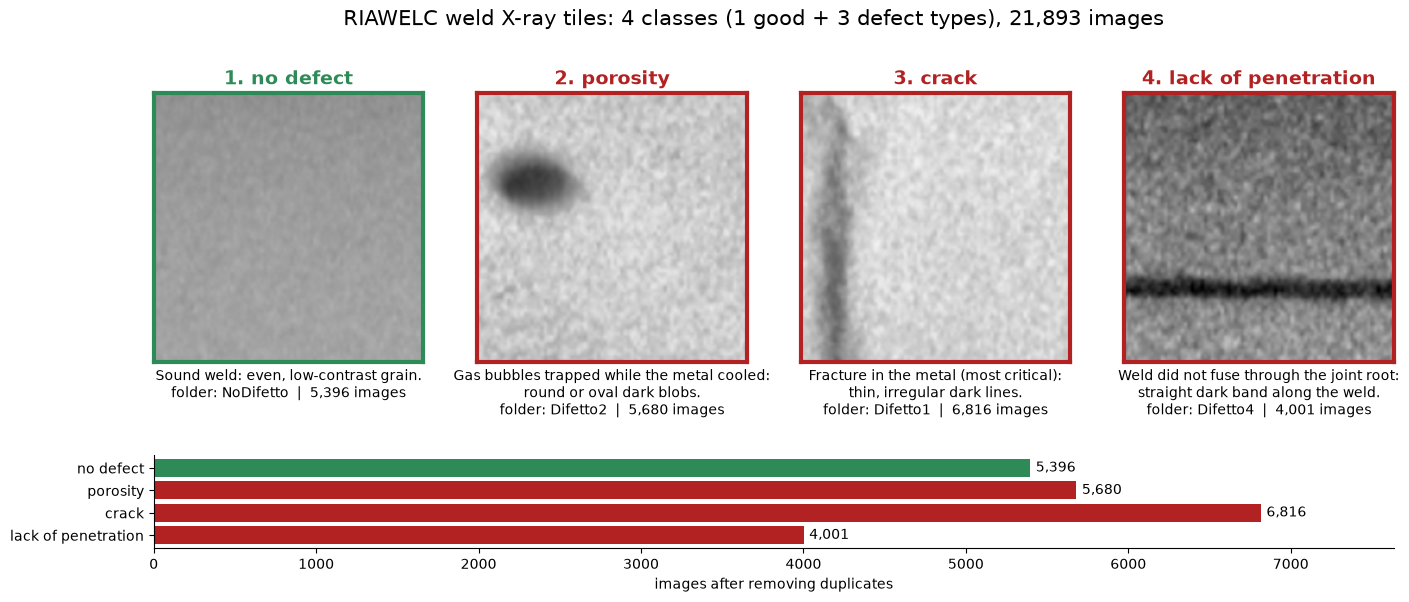

In [4]:
CLASS_INFO = {
    "no_defect":           ("NoDifetto", "Sound weld: even, low-contrast grain."),
    "porosity":            ("Difetto2",  "Gas bubbles trapped while the metal cooled:\nround or oval dark blobs."),
    "crack":               ("Difetto1",  "Fracture in the metal (most critical):\nthin, irregular dark lines."),
    "lack_of_penetration": ("Difetto4",  "Weld did not fuse through the joint root:\nstraight dark band along the weld."),
}
order = list(CLASS_INFO)
counts = df["label"].value_counts()

def typical_example(label):
    sub = df[df["label"] == label]
    return sub.iloc[(sub["std"] - sub["std"].median()).abs().argmin()]

fig = plt.figure(figsize=(16, 6.2))
grid = fig.add_gridspec(2, 4, height_ratios=[4, 1.2], hspace=0.35)
for i, label in enumerate(order):
    row = typical_example(label)
    ax = fig.add_subplot(grid[0, i])
    ax.imshow(Image.open(row["path"]), cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([]); ax.set_yticks([])
    folder, desc = CLASS_INFO[label]
    colour = "firebrick" if label != "no_defect" else "seagreen"
    ax.set_title(f"{i + 1}. {label.replace('_', ' ')}", fontsize=14, fontweight="bold", color=colour)
    for s in ax.spines.values():
        s.set_edgecolor(colour); s.set_linewidth(3)
    ax.set_xlabel(f"{desc}\nfolder: {folder}  |  {counts[label]:,} images", fontsize=10)

ax = fig.add_subplot(grid[1, :])
names = [l.replace("_", " ") for l in order][::-1]
values = [counts[l] for l in order][::-1]
bars = ax.barh(names, values, color=["firebrick"] * 3 + ["seagreen"])
ax.bar_label(bars, labels=[f"{v:,}" for v in values], padding=4)
ax.set_xlabel("images after removing duplicates")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, counts.max() * 1.12)

fig.suptitle(f"RIAWELC weld X-ray tiles: {len(order)} classes "
             f"(1 good + {len(order) - 1} defect types), {len(df):,} images", fontsize=15)
fig.savefig(FIGURES_DIR / "one_example_per_class.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Eight examples per class

Eight random tiles per class (fixed seed, so the whole team sees the same grid). The patch titles show the source radiograph.

- **no_defect** (`NoDifetto`): smooth, low-contrast grain.
- **crack** (`Difetto1`): thin, irregular, sometimes curved dark lines.
- **porosity** (`Difetto2`): round or oval dark blobs.
- **lack_of_penetration** (`Difetto4`): a straight dark band running along the weld.


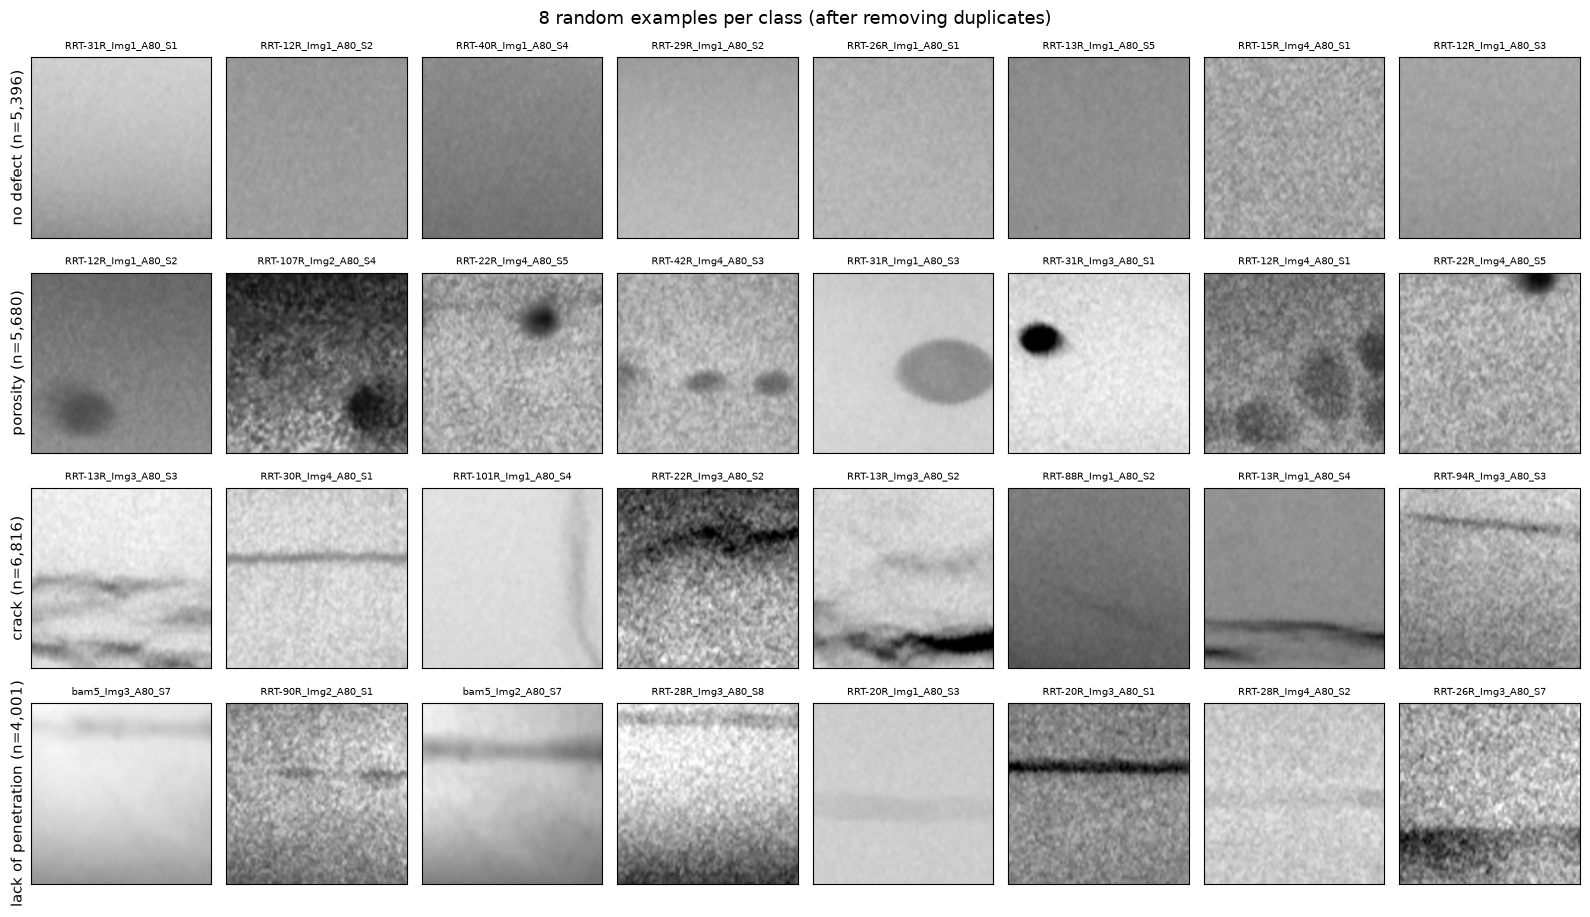

In [5]:
N_PER_CLASS = 8
labels = order  # same order as section 3

fig, axes = plt.subplots(len(labels), N_PER_CLASS, figsize=(2 * N_PER_CLASS, 2.3 * len(labels)))
for r, label in enumerate(labels):
    sample = df[df["label"] == label].sample(N_PER_CLASS, random_state=SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        ax = axes[r, c]
        ax.imshow(Image.open(row["path"]), cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(row["source"], fontsize=7)
        if c == 0:
            ax.set_ylabel(f"{label.replace('_', ' ')} (n={(df['label'] == label).sum():,})", fontsize=11)
fig.suptitle(f"{N_PER_CLASS} random examples per class (after removing duplicates)", fontsize=13)
fig.tight_layout()
FIGURES_DIR.mkdir(exist_ok=True)
fig.savefig(FIGURES_DIR / "samples_per_class.png", dpi=110, bbox_inches="tight")
plt.show()

### Brightness and contrast per class

Defect-free patches are much smoother (lower pixel standard deviation) than defect patches. Useful for an autoencoder, but it also means contrast alone separates the classes a lot.

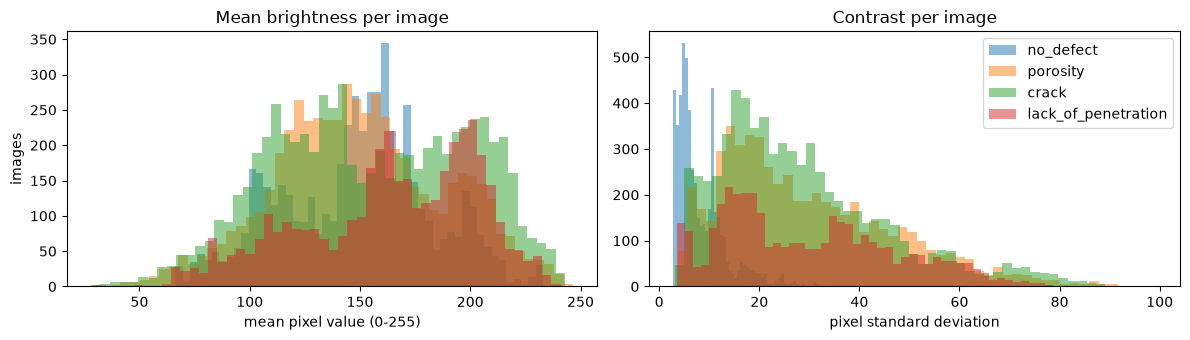

mean                                                 \
                      count   mean   std   min    25%    50%    75%    max   
label                                                                        
crack                6816.0  154.7  43.8  27.9  119.6  153.4  193.0  243.2   
lack_of_penetration  4001.0  163.6  39.7  30.7  135.9  168.1  196.5  241.0   
no_defect            5396.0  148.6  33.8  66.2  122.5  152.4  170.1  233.1   
porosity             5680.0  149.7  38.7  28.3  123.0  147.9  176.3  246.7   

                        std                                           
                      count  mean   std  min   25%   50%   75%   max  
label                                                                 
crack                6816.0  28.7  17.1  3.2  15.9  25.0  37.8  96.6  
lack_of_penetration  4001.0  29.9  17.2  3.5  15.7  27.3  41.9  83.4  
no_defect            5396.0   8.3   5.0  2.8   4.7   6.5  10.7  31.9  
porosity             5680.0  29.8  17.4  3.7  16.2  25.8  40.7  99.2

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label in labels:
    sub = df[df["label"] == label]
    axes[0].hist(sub["mean"], bins=50, alpha=0.5, label=label)
    axes[1].hist(sub["std"], bins=50, alpha=0.5, label=label)
axes[0].set(title="Mean brightness per image", xlabel="mean pixel value (0-255)", ylabel="images")
axes[1].set(title="Contrast per image", xlabel="pixel standard deviation")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "brightness_contrast_per_class.png", dpi=110, bbox_inches="tight")
plt.show()

df.groupby("label")[["mean", "std"]].describe().round(1)

## 5. Train / validation / test split by weld

The original split put tiles of the same X-ray in train, validation **and** test, so a model could recognise the weld instead of the defect. We build a new split.

**What is one "X-ray"?** The file name `RRT-13R_Img3_A80_S5_[14][49]` reads as: weld radiograph `RRT-13R`, image `Img3`, section `S5`, tile row 14, column 49. Sections and images of the same weld overlap visually, so the safe unit is the **weld**: all tiles of one weld go to exactly one split. There are only 29 welds, of very different sizes and defect mixes.

**How:** we try many random assignments of welds to train / validation / test and keep the one whose image counts per class come closest to **70 / 15 / 15**, with every class present in validation and test. Fixed seed, so the whole team gets the same split.

In [7]:
df["weld"] = df["source"].str.split("_").str[0]

per_weld = pd.crosstab(df["weld"], df["label"])[order]
per_weld["total"] = per_weld.sum(axis=1)
print(f"{len(per_weld)} welds")
per_weld.sort_values("total", ascending=False)

29 welds


label,no_defect,porosity,crack,lack_of_penetration,total
weld,,,,,
RRT-13R,191,70,1547,0,1808
RRT-99R,152,40,1506,0,1698
RRT-26R,353,458,0,877,1688
RRT-12R,817,851,0,0,1668
RRT-39R,471,1160,0,0,1631
RRT-94R,382,56,683,0,1121
RRT-20R,27,0,0,1044,1071
RRT-88R,119,190,749,0,1058
RRT-40R,632,203,145,0,980


In [8]:
SPLITS = ["train", "val", "test"]
TARGET = np.array([0.70, 0.15, 0.15])
N_TRIALS = 20_000

welds = per_weld.index.to_numpy()
class_counts = per_weld[order].to_numpy()          # welds x classes
class_totals = class_counts.sum(axis=0)

def split_cost(assign):
    # sum over classes and splits of |actual share - target share|; inf if a class is missing from val or test
    shares = np.stack([class_counts[assign == s].sum(axis=0) for s in range(3)]) / class_totals
    if (shares[1:] == 0).any():
        return np.inf
    return np.abs(shares - TARGET[:, None]).sum()

rng = np.random.default_rng(SEED)
best_cost, best_assign = np.inf, None
for _ in range(N_TRIALS):
    assign = rng.choice(3, size=len(welds), p=TARGET)
    cost = split_cost(assign)
    if cost < best_cost:
        best_cost, best_assign = cost, assign

weld_split = pd.Series(np.array(SPLITS)[best_assign], index=welds, name="split")
df["split"] = df["weld"].map(weld_split)

for s in SPLITS:
    print(f"{s:5s} ({(weld_split == s).sum():2d} welds): {', '.join(sorted(weld_split.index[weld_split == s]))}")
print(f"\nbest cost: {best_cost:.3f} (0 = exactly 70/15/15 for every class)")

train (20 welds): RRT-101R, RRT-102R, RRT-105R, RRT-107R, RRT-11R, RRT-12R, RRT-13R, RRT-15R, RRT-20R, RRT-22R, RRT-26R, RRT-27R, RRT-29R, RRT-39R, RRT-88R, RRT-90R, RRT-97R, RRT-98R, RRT-99R, bam5
val   ( 5 welds): RRT-09R, RRT-24R, RRT-30R, RRT-42R, RRT-94R
test  ( 4 welds): RRT-23R, RRT-28R, RRT-31R, RRT-40R

best cost: 0.343 (0 = exactly 70/15/15 for every class)


In [9]:
# Checks: every weld in exactly one split, no duplicate image across splits
assert df.groupby("weld")["split"].nunique().max() == 1
assert not df.duplicated("pixel_hash").any()

counts_split = pd.crosstab(df["split"], df["label"]).loc[SPLITS, order]
share = (counts_split / counts_split.sum() * 100).round(1)
summary_split = counts_split.astype(str) + " (" + share.astype(str) + "%)"
summary_split["total"] = counts_split.sum(axis=1)
summary_split

label,no_defect,porosity,crack,lack_of_penetration,total
split,,,,,
train,3783 (70.1%),4207 (74.1%),5175 (75.9%),2921 (73.0%),16086
val,747 (13.8%),523 (9.2%),1064 (15.6%),454 (11.3%),2788
test,866 (16.0%),950 (16.7%),577 (8.5%),626 (15.6%),3019


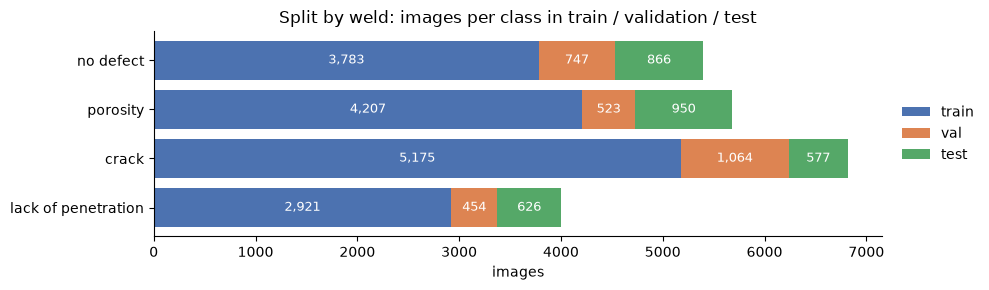

In [10]:
fig, ax = plt.subplots(figsize=(10, 3))
left = np.zeros(len(order))
colours = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}
for s in SPLITS:
    vals = counts_split.loc[s].to_numpy()
    ax.barh([l.replace("_", " ") for l in order], vals, left=left, color=colours[s], label=s)
    for y, (v, l) in enumerate(zip(vals, left)):
        ax.text(l + v / 2, y, f"{v:,}", ha="center", va="center", color="white", fontsize=9)
    left += vals
ax.invert_yaxis()
ax.set_xlabel("images")
ax.set_title("Split by weld: images per class in train / validation / test")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "split_by_weld.png", dpi=120, bbox_inches="tight")
plt.show()

### What each split is used for

| Split | no_defect | defects | Used for |
|---|---|---|---|
| **train** | yes | **not used** | teaching the autoencoder what a good weld looks like |
| **val** | yes | yes | early stopping (no_defect only) and choosing the low / check / high thresholds |
| **test** | yes | yes | the final, one-time evaluation |

Defect tiles from training welds are set aside: the autoencoder must never see a defect during training.

In [11]:
train_df = df[(df["split"] == "train") & (df["label"] == "no_defect")].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
unused = df[(df["split"] == "train") & (df["label"] != "no_defect")]

print(f"train : {len(train_df):6,} images (no_defect only)")
print(f"val   : {len(val_df):6,} images ({(val_df['label'] == 'no_defect').sum():,} no_defect + {(val_df['label'] != 'no_defect').sum():,} defects)")
print(f"test  : {len(test_df):6,} images ({(test_df['label'] == 'no_defect').sum():,} no_defect + {(test_df['label'] != 'no_defect').sum():,} defects)")
print(f"unused: {len(unused):6,} defect images from training welds")

# Save the split so later notebooks/scripts can reuse it (data/ is git-ignored; rerunning this notebook recreates it)
split_file = Path("../data/split.csv")
df[["path", "label", "weld", "source", "split"]].to_csv(split_file, index=False)
print("saved", split_file)

train :  3,783 images (no_defect only)
val   :  2,788 images (747 no_defect + 2,041 defects)
test  :  3,019 images (866 no_defect + 2,153 defects)
unused: 12,303 defect images from training welds
saved ..\data\split.csv


## 6. Step 4 – Preprocessing

**What we do**
- Load every tile of the three splits as greyscale, **resize** it, and scale pixels from 0–255 to **0–1** (the autoencoder ends with a sigmoid, so its output is also 0–1).
- We prepare **two resolutions**: **128 px** (main) and **64 px** (comparison). The original tiles are 227 px; 128 and 64 can be halved cleanly down to 8 × 8 inside the network.
- Result: tensors of shape `(N, 1, H, W)` (images, channels, height, width), as in the teacher's notebook.
- **Labels for evaluation:** `0` = no_defect, `1` = any defect. The autoencoder never uses them; we only need them to measure how well it flags defects.

**Why compare 128 vs 64?** At 64 px a thin crack can shrink to less than a pixel and disappear, so 128 px should help cracks. But no_defect tiles are mostly grainy X-ray noise that an autoencoder cannot copy, and more pixels means more noise in the error. Only the experiment can tell which wins.

In [12]:
import time
from torch import nn
from sklearn.metrics import precision_score, recall_score, roc_auc_score

SIZES = [128, 64]
DEFECTS = ["porosity", "crack", "lack_of_penetration"]


def load_images(paths, size):
    # greyscale -> resize to size x size -> float 0-1, shape (N, 1, size, size)
    arr = np.empty((len(paths), 1, size, size), dtype=np.float32)
    for i, p in enumerate(paths):
        img = Image.open(p).convert("L").resize((size, size), Image.Resampling.BILINEAR)
        arr[i, 0] = np.asarray(img, dtype=np.float32) / 255.0
    return torch.from_numpy(arr)


start = time.time()
X = {size: {"train": load_images(train_df["path"], size),
            "val": load_images(val_df["path"], size),
            "test": load_images(test_df["path"], size)} for size in SIZES}

# 1 = defect, 0 = no_defect (only used to evaluate, never to train)
labels_val = val_df["label"].to_numpy()
labels_test = test_df["label"].to_numpy()
y_val = (labels_val != "no_defect").astype(int)
y_test = (labels_test != "no_defect").astype(int)

print(f"loaded in {time.time() - start:.0f} s")
for size in SIZES:
    print(f"{size:3d} px:", {k: tuple(v.shape) for k, v in X[size].items()})
print(f"pixel range: {float(X[128]['train'].min()):.2f} – {float(X[128]['train'].max()):.2f}")

loaded in 11 s
128 px: {'train': (3783, 1, 128, 128), 'val': (2788, 1, 128, 128), 'test': (3019, 1, 128, 128)}
 64 px: {'train': (3783, 1, 64, 64), 'val': (2788, 1, 64, 64), 'test': (3019, 1, 64, 64)}
pixel range: 0.17 – 1.00


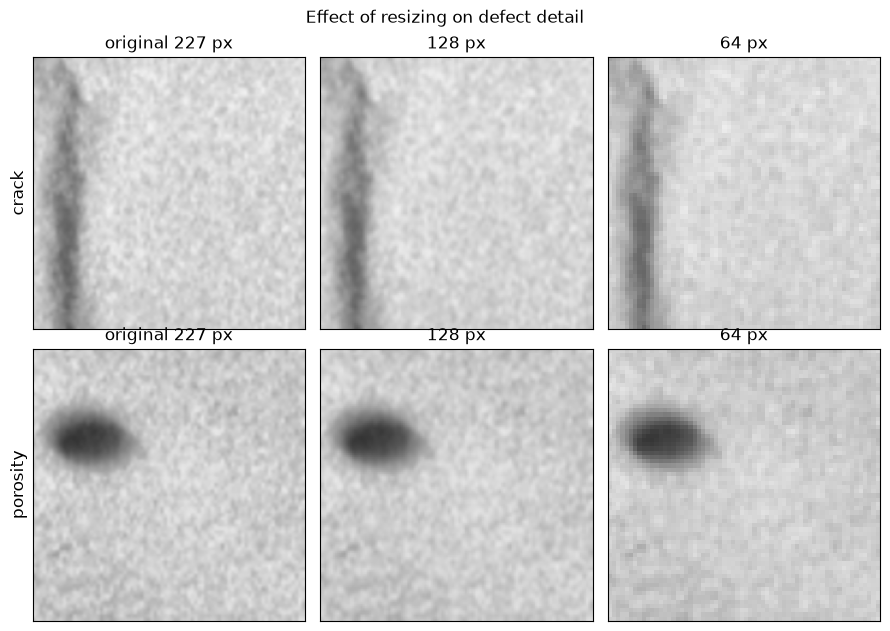

In [13]:
# What resizing does to fine detail: original 227 px vs 128 px vs 64 px
examples = [typical_example("crack"), typical_example("porosity")]
fig, axes = plt.subplots(len(examples), 3, figsize=(9, 3.2 * len(examples)))
for r, row in enumerate(examples):
    original = Image.open(row["path"])
    for c, (title, img) in enumerate([("original 227 px", original),
                                      ("128 px", original.resize((128, 128), Image.Resampling.BILINEAR)),
                                      ("64 px", original.resize((64, 64), Image.Resampling.BILINEAR))]):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(title)
    axes[r, 0].set_ylabel(row["label"].replace("_", " "), fontsize=12)
fig.suptitle("Effect of resizing on defect detail")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "resize_effect.png", dpi=110, bbox_inches="tight")
plt.show()

## 7. Step 5 – The models

Two kinds of autoencoder, adapted from the teacher's notebook to our image sizes:

- **`ConvAE` (convolutional):** the encoder halves the image with stride-2 convolutions until it is 8 × 8 (128 → 64 → 32 → 16 → 8, so 4 layers at 128 px and 3 at 64 px), then a linear layer makes the **code** (`latent_dim` numbers). The decoder mirrors it with transposed convolutions. We add **BatchNorm** between layers, which makes training on real X-rays more stable. Filters are shared over the whole image, so the model stays small.
- **`DenseAE` (fully connected):** flattens the image (128 × 128 = 16,384 numbers), squeezes it through a hidden layer of 512 to the code, and back. Every pixel connects to every neuron, so it has many more parameters and ignores which pixels are neighbours.

Both end with a **sigmoid** so outputs are 0–1 like the inputs.

**The four setups** (same data, split, seed, training recipe):

| Setup | Size | Model | Latent | Question it answers |
|---|---|---|---|---|
| A | 128 px | Conv AE | 32 | main candidate |
| B | 128 px | Conv AE | 128 | does a bigger code help or let defects through? |
| C | 128 px | Dense AE | 32 | convolutional vs dense |
| D | 64 px | Conv AE | 32 | does resolution matter? |

In [14]:
class ConvAE(nn.Module):
    def __init__(self, image_size=128, latent_dim=32, channels=(32, 64, 128, 128)):
        super().__init__()
        n_down = int(np.log2(image_size // 8))           # halve until 8 x 8: 4 layers at 128 px, 3 at 64 px
        chans = [1] + list(channels[:n_down])
        encoder = []
        for c_in, c_out in zip(chans[:-1], chans[1:]):
            encoder += [nn.Conv2d(c_in, c_out, 3, stride=2, padding=1), nn.BatchNorm2d(c_out), nn.ReLU()]
        self.encoder = nn.Sequential(*encoder, nn.Flatten(), nn.Linear(chans[-1] * 8 * 8, latent_dim))

        decoder = [nn.Linear(latent_dim, chans[-1] * 8 * 8), nn.ReLU(), nn.Unflatten(1, (chans[-1], 8, 8))]
        rev = chans[::-1]
        for i, (c_in, c_out) in enumerate(zip(rev[:-1], rev[1:])):
            decoder.append(nn.ConvTranspose2d(c_in, c_out, 3, stride=2, padding=1, output_padding=1))
            is_last = i == len(rev) - 2
            decoder += [nn.Sigmoid()] if is_last else [nn.BatchNorm2d(c_out), nn.ReLU()]
        self.decoder = nn.Sequential(*decoder)

    def forward(self, x):
        return self.decoder(self.encoder(x))


class DenseAE(nn.Module):
    def __init__(self, image_size=128, latent_dim=32, hidden=512):
        super().__init__()
        n_pixels = image_size * image_size
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(n_pixels, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n_pixels), nn.Sigmoid(),
                                     nn.Unflatten(1, (1, image_size, image_size)))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


SETUPS = [
    {"setup": "A", "size": 128, "model": "Conv AE",  "latent": 32,  "build": lambda: ConvAE(128, 32)},
    {"setup": "B", "size": 128, "model": "Conv AE",  "latent": 128, "build": lambda: ConvAE(128, 128)},
    {"setup": "C", "size": 128, "model": "Dense AE", "latent": 32,  "build": lambda: DenseAE(128, 32)},
    {"setup": "D", "size": 64,  "model": "Conv AE",  "latent": 32,  "build": lambda: ConvAE(64, 32)},
]
for s in SETUPS:
    m = s["build"]()
    out = m(torch.zeros(2, 1, s["size"], s["size"]))
    print(f"setup {s['setup']}: {s['model']:8s} {s['size']:3d} px, latent {s['latent']:3d} -> "
          f"{n_params(m):>10,} parameters, output {tuple(out.shape)}")

setup A: Conv AE  128 px, latent  32 ->  1,014,049 parameters, output (2, 1, 128, 128)
setup B: Conv AE  128 px, latent 128 ->  2,587,009 parameters, output (2, 1, 128, 128)
setup C: Dense AE 128 px, latent  32 -> 16,827,424 parameters, output (2, 1, 128, 128)
setup D: Conv AE   64 px, latent  32 ->    718,369 parameters, output (2, 1, 64, 64)


## 8. Step 6 – Training on no_defect tiles only

**Recipe (identical for all four setups):**
- **Data:** only the 3,783 **no_defect** tiles of the training welds. The model never sees a defect.
- **Loss:** mean squared error (MSE) between output and input: the **reconstruction error**.
- **Optimiser:** Adam, learning rate 0.001, batches of 64.
- **Augmentation:** random horizontal and vertical flips of each batch. A flipped sound weld is still a sound weld, so this shows the model more variety for free.
- **Early stopping:** after every epoch we measure the MSE on the **no_defect validation tiles**. We keep the best epoch and stop when it has not improved for 6 epochs (max 60). This avoids overfitting without guessing the number of epochs.
- Same seed for every setup, so the comparison is fair.

The best weights of each setup are saved to `models/` (git-ignored; model files go to Hugging Face, not GitHub).

In [15]:
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


@torch.no_grad()
def reconstruct(model, X, batch_size=256):
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(device)).cpu() for i in range(0, len(X), batch_size)])


@torch.no_grad()
def reconstruction_error(model, X, batch_size=256):
    # one number per image: mean squared difference between input and reconstruction
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(device)
        errors.append(((model(batch) - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors).numpy()


def train_autoencoder(model, X_train, X_val_normal, max_epochs=60, patience=6, lr=1e-3, batch_size=64):
    torch.manual_seed(SEED)
    gen = torch.Generator().manual_seed(SEED)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state, best_epoch, history = np.inf, None, 0, []
    start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        total = 0.0
        order = torch.randperm(len(X_train), generator=gen)
        for i in range(0, len(order), batch_size):
            x = X_train[order[i:i + batch_size]].to(device)
            if torch.rand(1, generator=gen) < 0.5:          # augmentation: random flips
                x = x.flip(3)
            if torch.rand(1, generator=gen) < 0.5:
                x = x.flip(2)
            loss = nn.functional.mse_loss(model(x), x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        val_mse = reconstruction_error(model, X_val_normal).mean()
        history.append({"epoch": epoch, "train_mse": total / len(X_train), "val_mse": val_mse})
        if val_mse < best_val:
            best_val, best_epoch = val_mse, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), time.time() - start, best_epoch


MODELS_DIR.mkdir(exist_ok=True)
is_normal_val = y_val == 0
trained = {}
for s in SETUPS:
    data = X[s["size"]]
    torch.manual_seed(SEED)                      # same starting weights every run
    model, hist, seconds, best_epoch = train_autoencoder(s["build"](), data["train"], data["val"][is_normal_val])
    trained[s["setup"]] = {**s, "net": model, "history": hist, "seconds": seconds, "best_epoch": best_epoch}
    torch.save(model.state_dict(), MODELS_DIR / f"setup_{s['setup']}.pt")
    print(f"setup {s['setup']}: best epoch {best_epoch:2d} of {len(hist):2d}, "
          f"val MSE {hist['val_mse'].min():.5f}, {seconds:5.1f} s")

setup A: best epoch 14 of 20, val MSE 0.00027,  11.5 s


setup B: best epoch  6 of 12, val MSE 0.00038,   6.1 s


setup C: best epoch  5 of 11, val MSE 0.00035,   2.7 s


setup D: best epoch 21 of 27, val MSE 0.00020,   8.1 s


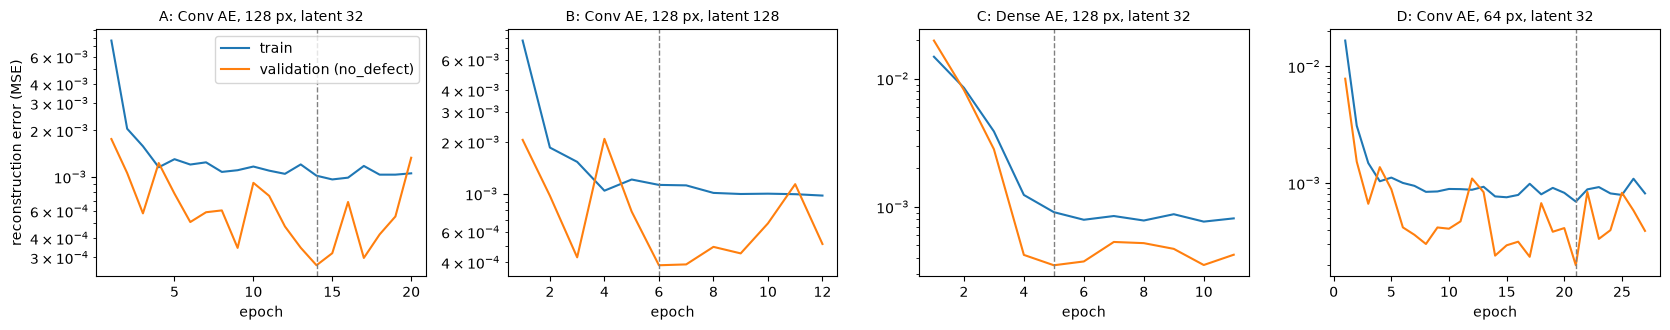

In [16]:
fig, axes = plt.subplots(1, len(trained), figsize=(4.2 * len(trained), 3.4), sharey=False)
for ax, (name, t) in zip(axes, trained.items()):
    h = t["history"]
    ax.plot(h["epoch"], h["train_mse"], label="train")
    ax.plot(h["epoch"], h["val_mse"], label="validation (no_defect)")
    ax.axvline(t["best_epoch"], color="grey", ls="--", lw=1)
    ax.set_title(f"{name}: {t['model']}, {t['size']} px, latent {t['latent']}", fontsize=10)
    ax.set_xlabel("epoch"); ax.set_yscale("log")
axes[0].set_ylabel("reconstruction error (MSE)")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training_curves.png", dpi=110, bbox_inches="tight")
plt.show()

### Step 6 – what we see

- **Training is fast:** 3 to 11 seconds per setup on the GPU. All four reach a validation error of about **0.0002–0.0004** on sound tiles: they rebuild a sound weld almost perfectly.
- **The validation curve is noisy** (it jumps up and down between epochs). The validation set is small (747 sound tiles from 5 welds) and BatchNorm makes the model's behaviour shift a little each epoch. Early stopping keeps the best epoch, but with patience 6 setups B and C stopped early (epoch 5–6), so they may be slightly under-trained. That is a limitation of this comparison.
![Training curves](../figures/training_curves.png)

- **Validation error is lower than training error.** This is not a bug: the training loss is measured with random flips and BatchNorm in training mode, and the sound tiles of the validation welds happen to be smoother.

## 9. Step 7 – Compare the setups on validation and pick the best

For each setup we score every **validation** tile (no_defect and defects) with its reconstruction error, then measure:
- **ROC AUC** (defect vs no_defect): how well the error separates the two groups over *all* thresholds. 1.0 = perfect, 0.5 = coin flip. **This is our selection metric.** It is comparable across 64 and 128 px, while raw MSE is not.
- **AUC per defect type:** porosity, crack, lack of penetration separately.
- **Threshold:** as in the teacher's notebook, the **95th percentile** of the error on no_defect validation tiles: by design about 5% of sound tiles are flagged (false alarms).
- **Precision and recall** at that threshold.

**Baseline:** the contrast shortcut from section 3. If simply using each tile's pixel standard deviation as the score works as well, the autoencoder adds little. The autoencoder should beat it.

The **test set is not touched** in this step: the winner is chosen on validation only.

In [17]:
def per_defect_auc(scores, labels):
    normal = labels == "no_defect"
    return {d: roc_auc_score(labels[normal | (labels == d)] == d, scores[normal | (labels == d)]) for d in DEFECTS}


def evaluate(scores_val, scores_test=None):
    threshold = float(np.quantile(scores_val[y_val == 0], 0.95))
    row = {"val ROC AUC": roc_auc_score(y_val, scores_val)}
    row.update({f"val AUC {d}": v for d, v in per_defect_auc(scores_val, labels_val).items()})
    pred = (scores_val > threshold).astype(int)
    row.update({"val precision": precision_score(y_val, pred), "val recall": recall_score(y_val, pred),
                "threshold": threshold})
    return row


rows = []
for name, t in trained.items():
    data = X[t["size"]]
    t["err_val"] = reconstruction_error(t["net"], data["val"])
    rows.append({"setup": name, "model": t["model"], "size": t["size"], "latent": t["latent"],
                 "parameters": n_params(t["net"]), "training time (s)": round(t["seconds"], 1),
                 "best epoch": t["best_epoch"], "val MSE (no_defect)": t["err_val"][y_val == 0].mean(),
                 **evaluate(t["err_val"])})

# Baseline: contrast only (pixel standard deviation of the tile), no model
baseline_val = val_df["std"].to_numpy()
rows.append({"setup": "baseline", "model": "pixel std (no model)", "size": 227, **evaluate(baseline_val)})

val_table = pd.DataFrame(rows).set_index("setup")
BEST = val_table.drop("baseline")["val ROC AUC"].idxmax()
print(f"Best setup on validation ROC AUC: {BEST}")
val_table.style.format({"latent": "{:.0f}", "parameters": "{:,.0f}", "training time (s)": "{:.1f}", "best epoch": "{:.0f}",
                        "val MSE (no_defect)": "{:.5f}", "threshold": "{:.5f}"}, precision=3, na_rep="–").highlight_max(
    subset=["val ROC AUC", "val AUC porosity", "val AUC crack", "val AUC lack_of_penetration"], color="#c6efce")

Best setup on validation ROC AUC: D


,model,size,latent,parameters,training time (s),best epoch,val MSE (no_defect),val ROC AUC,val AUC porosity,val AUC crack,val AUC lack_of_penetration,val precision,val recall,threshold
setup,,,,,,,,,,,,,,
A,Conv AE,128,32,"1,014,049",11.5,14,0.00027,0.987,0.992,0.980,0.997,0.980,0.928,0.00048
B,Conv AE,128,128,"2,587,009",6.1,6,0.00038,0.986,0.992,0.979,0.997,0.980,0.931,0.00062
C,Dense AE,128,32,"16,827,424",2.7,5,0.00035,0.977,0.987,0.966,0.992,0.979,0.873,0.00089
D,Conv AE,64,32,"718,369",8.1,21,0.00020,0.990,0.994,0.985,0.998,0.981,0.958,0.00034
baseline,pixel std (no model),227,–,–,–,–,–,0.946,0.949,0.926,0.991,0.978,0.824,12.20585


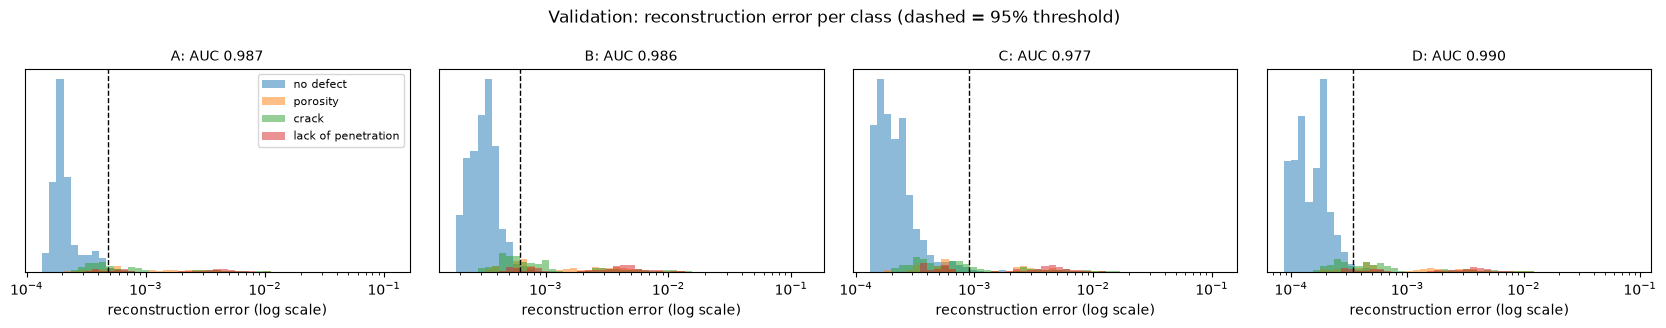

In [18]:
fig, axes = plt.subplots(1, len(trained), figsize=(4.2 * len(trained), 3.3))
for ax, (name, t) in zip(axes, trained.items()):
    e = t["err_val"]
    bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 50)
    for label in order:
        ax.hist(e[labels_val == label], bins=bins, alpha=0.5, density=True, label=label.replace("_", " "))
    ax.axvline(val_table.loc[name, "threshold"], color="black", ls="--", lw=1)
    ax.set_title(f"{name}: AUC {val_table.loc[name, 'val ROC AUC']:.3f}", fontsize=10)
    ax.set_xscale("log"); ax.set_xlabel("reconstruction error (log scale)"); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Validation: reconstruction error per class (dashed = 95% threshold)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "val_error_histograms.png", dpi=110, bbox_inches="tight")
plt.show()

### Step 7 – which setup is best and why

| | A: Conv 128, latent 32 | B: Conv 128, latent 128 | C: Dense 128, latent 32 | **D: Conv 64, latent 32** | baseline (contrast) |
|---|---|---|---|---|---|
| Val ROC AUC | 0.987 | 0.986 | 0.977 | **0.990** | 0.946 |
| AUC porosity | 0.992 | 0.992 | 0.987 | **0.994** | 0.949 |
| AUC crack | 0.980 | 0.979 | 0.966 | **0.985** | 0.926 |
| AUC lack of penetration | 0.997 | 0.997 | 0.992 | **0.998** | 0.991 |
| Recall at 95% threshold | 0.928 | 0.931 | 0.873 | **0.958** | 0.824 |
| Parameters | 1.0 M | 2.6 M | 16.8 M | **0.7 M** | – |

**Winner: setup D (convolutional, 64 px, latent 32).** It has the highest AUC overall and for every defect type, the highest recall, and the fewest parameters.

![Validation error histograms](../figures/val_error_histograms.png)

In every setup the sound tiles (blue) sit in a narrow peak at very low error, left of the dashed threshold, and the defects spread to the right. D has the cleanest separation.

**Why each comparison came out this way**
- **All autoencoders beat the contrast baseline** (0.977–0.990 vs 0.946), most clearly on **cracks** (0.985 vs 0.926). So the model learns more than "defect tiles are more contrasted". Lack of penetration is easy even for the baseline (0.991), because it is a strong dark band.
- **64 px beats 128 px (D vs A).** Our worry was that thin cracks vanish at 64 px. They did not: crack AUC is even slightly higher (0.985 vs 0.980). Halving the resolution averages away the X-ray **grain**, which the autoencoder cannot copy anyway, so sound tiles get a cleaner, lower error (0.00020 vs 0.00027) while defects still stand out. The defects are large enough to survive the resize (see the resize figure in Step 4).
- **A bigger code does not help (B vs A):** latent 128 gives AUC 0.986 vs 0.987, with 2.5× more parameters. More room in the bottleneck lets the model copy more of everything, defects included, so the gap between sound and defect does not grow. This is the effect the teacher's notebook warns about.
- **Dense is worst (C):** AUC 0.977 with 17× more parameters than A. A dense layer ignores which pixels are neighbours, so it is worse at telling a real shape (crack, pore) from grain.
- **Cracks are the hardest defect** for every setup (lowest AUC): they are thin and faint, so they change few pixels.

## 10. Step 8 – Final evaluation on the test set

The winner and its threshold are now **fixed** from validation. We run the test welds (never used for training or choices) and report the same metrics. For the README table we also report the test numbers of the other setups, computed **after** the choice was made, so they could not influence it.

In [19]:
test_rows = []
for name, t in trained.items():
    t["err_test"] = reconstruction_error(t["net"], X[t["size"]]["test"])
    thr = val_table.loc[name, "threshold"]
    pred = (t["err_test"] > thr).astype(int)
    test_rows.append({"setup": name, "test MSE (no_defect)": t["err_test"][y_test == 0].mean(),
                      "test ROC AUC": roc_auc_score(y_test, t["err_test"]),
                      **{f"test AUC {d}": v for d, v in per_defect_auc(t["err_test"], labels_test).items()},
                      "test precision": precision_score(y_test, pred), "test recall": recall_score(y_test, pred)})
baseline_test = test_df["std"].to_numpy()
thr = val_table.loc["baseline", "threshold"]
test_rows.append({"setup": "baseline", "test ROC AUC": roc_auc_score(y_test, baseline_test),
                  **{f"test AUC {d}": v for d, v in per_defect_auc(baseline_test, labels_test).items()},
                  "test precision": precision_score(y_test, baseline_test > thr),
                  "test recall": recall_score(y_test, baseline_test > thr)})
test_table = pd.DataFrame(test_rows).set_index("setup")

# The table for the README (same columns as the "Setups compared" table)
readme_table = pd.DataFrame({
    "Setup": [f"{k}: {val_table.loc[k, 'model']}, {int(val_table.loc[k, 'size'])} px"
              + (f", latent {int(val_table.loc[k, 'latent'])}" if k != "baseline" else "") for k in val_table.index],
    "Parameters": val_table["parameters"].map(lambda v: "–" if pd.isna(v) else f"{int(v):,}").to_numpy(),
    "Training time": val_table["training time (s)"].map(lambda v: "–" if pd.isna(v) else f"{v:.0f} s").to_numpy(),
    "Validation error": val_table["val MSE (no_defect)"].map(lambda v: "–" if pd.isna(v) else f"{v:.5f}").to_numpy(),
    "Test error": test_table["test MSE (no_defect)"].map(lambda v: "–" if pd.isna(v) else f"{v:.5f}").to_numpy(),
    "Val ROC AUC": val_table["val ROC AUC"].map("{:.3f}".format).to_numpy(),
    "Test ROC AUC": test_table["test ROC AUC"].map("{:.3f}".format).to_numpy(),
    "Precision": test_table["test precision"].map("{:.3f}".format).to_numpy(),
    "Recall": test_table["test recall"].map("{:.3f}".format).to_numpy(),
}, index=val_table.index)
print(f"Winner (chosen on validation): setup {BEST}")
test_table.style.format({"test MSE (no_defect)": "{:.5f}"}, precision=3, na_rep="–")

Winner (chosen on validation): setup D


,test MSE (no_defect),test ROC AUC,test AUC porosity,test AUC crack,test AUC lack_of_penetration,test precision,test recall
setup,,,,,,,
A,0.00023,0.998,1.000,0.997,0.997,1.000,0.964
B,0.00031,0.999,0.999,0.999,0.998,1.000,0.967
C,0.00025,1.000,0.999,1.000,1.000,1.000,0.972
D,0.00018,0.999,0.999,0.999,0.999,0.994,0.984
baseline,–,0.936,0.950,0.906,0.943,0.926,0.879


In [20]:
readme_table

,Setup,Parameters,Training time,Validation error,Test error,Val ROC AUC,Test ROC AUC,Precision,Recall
setup,,,,,,,,,
A,"A: Conv AE, 128 px, latent 32","1,014,049",12 s,0.00027,0.00023,0.987,0.998,1.000,0.964
B,"B: Conv AE, 128 px, latent 128","2,587,009",6 s,0.00038,0.00031,0.986,0.999,1.000,0.967
C,"C: Dense AE, 128 px, latent 32","16,827,424",3 s,0.00035,0.00025,0.977,1.000,1.000,0.972
D,"D: Conv AE, 64 px, latent 32","718,369",8 s,0.00020,0.00018,0.990,0.999,0.994,0.984
baseline,"baseline: pixel std (no model), 227 px",–,–,–,–,0.946,0.936,0.926,0.879


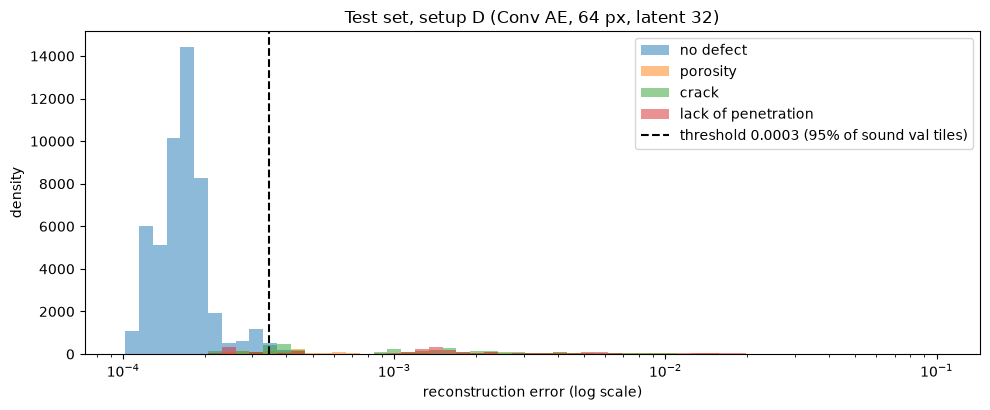

,images,mean_error,share_flagged
label,,,
no_defect,866,0.0002,0.0150
porosity,950,0.0168,0.9863
crack,577,0.0074,0.9775
lack_of_penetration,626,0.0103,0.9856


In [21]:
# Winner on the test set: error distribution per class and share flagged
best = trained[BEST]
thr = val_table.loc[BEST, "threshold"]
e = best["err_test"]

fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.logspace(np.log10(e.min()), np.log10(e.max()), 60)
for label in order:
    ax.hist(e[labels_test == label], bins=bins, alpha=0.5, density=True, label=label.replace("_", " "))
ax.axvline(thr, color="black", ls="--", label=f"threshold {thr:.4f} (95% of sound val tiles)")
ax.set_xscale("log")
ax.set(xlabel="reconstruction error (log scale)", ylabel="density",
       title=f"Test set, setup {BEST} ({best['model']}, {best['size']} px, latent {best['latent']})")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "test_error_histogram_best.png", dpi=110, bbox_inches="tight")
plt.show()

pd.DataFrame({"label": labels_test, "error": e, "flagged": e > thr}).groupby("label") \
    .agg(images=("error", "size"), mean_error=("error", "mean"), share_flagged=("flagged", "mean")).loc[order].round(4)

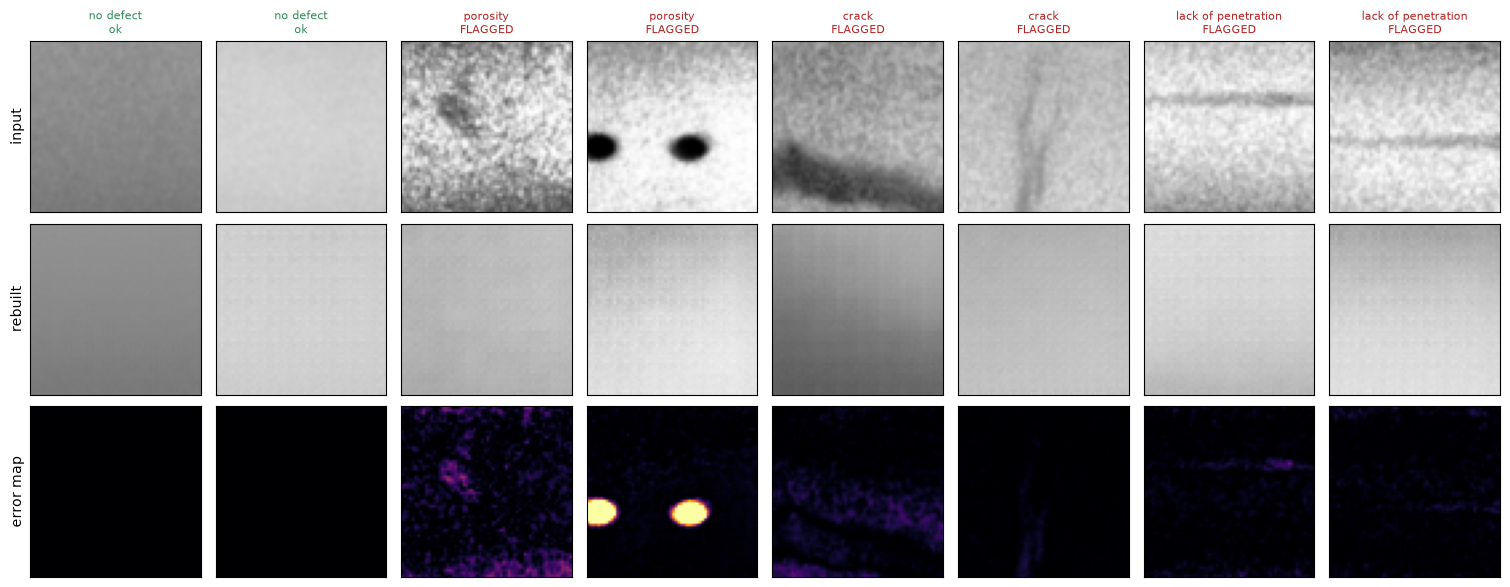

In [22]:
# What the winner sees: input, reconstruction and error map (where it fails), two test tiles per class
rng_pick = np.random.default_rng(SEED)
picks = [i for label in order for i in rng_pick.choice(np.where(labels_test == label)[0], 2, replace=False)]
inputs = X[best["size"]]["test"][picks]
outputs = reconstruct(best["net"], inputs)
error_map = (outputs - inputs) ** 2

fig, axes = plt.subplots(3, len(picks), figsize=(1.9 * len(picks), 6))
for c, i in enumerate(picks):
    for r, (img, kw) in enumerate([(inputs[c, 0], dict(cmap="gray", vmin=0, vmax=1)),
                                   (outputs[c, 0], dict(cmap="gray", vmin=0, vmax=1)),
                                   (error_map[c, 0], dict(cmap="inferno", vmin=0, vmax=float(error_map.max()) * 0.5))]):
        axes[r, c].imshow(img, **kw)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    flag = "FLAGGED" if e[i] > thr else "ok"
    axes[0, c].set_title(f"{labels_test[i].replace('_', ' ')}\n{flag}", fontsize=8,
                         color="firebrick" if e[i] > thr else "seagreen")
for r, name in enumerate(["input", "rebuilt", "error map"]):
    axes[r, 0].set_ylabel(name)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_maps_best.png", dpi=110, bbox_inches="tight")
plt.show()

### Step 8 – results on the test set

- **Setup D on the 4 unseen test welds:** ROC AUC **0.999**, precision **0.994**, recall **0.984**. With the 95% threshold it flags **98.6% of porosity, 97.8% of cracks and 98.6% of lack-of-penetration** tiles, and only **1.5% of sound tiles** (false alarms).
- **All autoencoders score 0.998–1.000 on test** and again beat the contrast baseline (0.936). D has the highest recall (0.984 vs 0.964–0.972), the number that matters most for safety.

![Test error histogram, setup D](../figures/test_error_histogram_best.png)
- **Test is easier than validation** (0.999 vs 0.990). With only 4 test welds this depends on which welds landed there: the honest summary is "about 0.99 AUC on unseen welds", not 0.999.
- **Precision looks very high partly because test has 2.5× more defect tiles than sound ones.** In a real factory most welds are sound, so the share of false alarms (1.5% here, ~5% by design of the threshold) matters more than precision.

![Error maps, setup D](../figures/error_maps_best.png)

**What the error maps show:** the autoencoder rebuilds every tile as a smooth grey gradient, i.e. what a sound weld looks like. Pores light up clearly as bright spots; cracks and lack of penetration show as faint lines. On very grainy radiographs the error is spread over the grain as well, so part of the score there comes from texture rather than the defect itself.

**Limitations**
- Only 29 welds from one lab: results may not transfer to other X-ray equipment.
- Tiles are labelled as a whole, so we cannot check whether the error map points at the right spot, only whether the tile is flagged.
- The noisy validation curve made early stopping stop B and C early; a learning-rate schedule or more patience could narrow the gap.
- The score is a screening aid, not an accept/reject decision under a welding standard.

## 11. Step 9 – Save the winning model for the model server

On Tuesday the model goes online as a **model server** (teacher's notebook 2). We save everything it needs into `model_app/`:

| File | Contents | Why |
|---|---|---|
| `anomaly_ae.onnx` | The model in **ONNX** format: architecture **and** weights in one file | The server runs it with ONNX Runtime, without PyTorch (PyTorch alone needs ~280 MB of the 512 MB a free server gets) |
| `anomaly_ae.pt` | The PyTorch weights (`state_dict`) | To train further in PyTorch later |
| `anomaly_ae_config.json` | Image size, preprocessing, threshold, how to compute the score, results | The server must prepare inputs **exactly** as in training, or it gives wrong answers without any error message |
| `examples/*.png` | One original test tile per class | Example inputs for the server's page |

**What the server will do with an uploaded tile:** greyscale → resize to 64 × 64 → pixels / 255 → run the ONNX model → **score** = mean of (input − output)² → compare with the threshold. The **error map** is (input − output)² per pixel, the heatmap of where to look.

`.onnx` and `.pt` files are git-ignored: they go to Hugging Face, not GitHub. The example tiles are also git-ignored because the dataset must not be re-uploaded (see the README).

In [23]:
import json

MODEL_APP_DIR = Path("../model_app")
(MODEL_APP_DIR / "examples").mkdir(parents=True, exist_ok=True)

best = trained[BEST]
IMAGE_SIZE = best["size"]
THRESHOLD = float(val_table.loc[BEST, "threshold"])
model_cpu = best["net"].cpu().eval()

# 1) PyTorch weights
torch.save(model_cpu.state_dict(), MODEL_APP_DIR / "anomaly_ae.pt")

# 2) ONNX: input "image" (N, 1, 64, 64) floats 0-1 -> output "reconstruction" with the same shape.
#    dynamic_shapes: the number of images per call (N) may change.
example_input = X[IMAGE_SIZE]["test"][:1]
torch.onnx.export(model_cpu, (example_input,), MODEL_APP_DIR / "anomaly_ae.onnx",
                  input_names=["image"], output_names=["reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)

# 3) Config: everything the server needs to prepare inputs and read the output
test_metrics = test_table.loc[BEST]
config = {
    "model": "ConvAE (convolutional autoencoder)",
    "setup": f"{BEST}: {best['model']}, {IMAGE_SIZE} px, latent {best['latent']}",
    "latent_dim": best["latent"],
    "image_size": IMAGE_SIZE,
    "input": {"name": "image", "shape": ["batch", 1, IMAGE_SIZE, IMAGE_SIZE], "dtype": "float32"},
    "output": {"name": "reconstruction", "shape": ["batch", 1, IMAGE_SIZE, IMAGE_SIZE]},
    "preprocessing": f"greyscale (PIL mode 'L'), resize to {IMAGE_SIZE}x{IMAGE_SIZE} with bilinear interpolation, "
                     "pixels divided by 255 (0-1), shape (1, 1, H, W)",
    "score": "anomaly score = mean over pixels of (input - reconstruction)^2",
    "error_map": "(input - reconstruction)^2 per pixel: where the model fails to rebuild the tile",
    "threshold": THRESHOLD,
    "threshold_rule": "95th percentile of the score on no_defect validation tiles (about 5% false alarms by design)",
    "decision": "score > threshold -> flag the tile for inspection",
    "normal_class": "no_defect",
    "anomaly_classes_in_test": DEFECTS,
    "validation_roc_auc": round(float(val_table.loc[BEST, "val ROC AUC"]), 3),
    "test_roc_auc": round(float(test_metrics["test ROC AUC"]), 3),
    "test_precision": round(float(test_metrics["test precision"]), 3),
    "test_recall": round(float(test_metrics["test recall"]), 3),
    "data": "RIAWELC weld radiographs (Totino, Spagnolo and Perri). Tiles of 227x227 px. Not redistributed.",
}
(MODEL_APP_DIR / "anomaly_ae_config.json").write_text(json.dumps(config, indent=2))

# 4) Example inputs: one original test tile per class (the server receives raw tiles, not preprocessed ones).
#    We pick the tile with the MEDIAN score of its class, i.e. a typical case, not a lucky or unlucky one.
for label in order:
    idx = np.where(labels_test == label)[0]
    typical = idx[np.argsort(best["err_test"][idx])[len(idx) // 2]]
    Image.open(test_df.loc[typical, "path"]).save(MODEL_APP_DIR / "examples" / f"{label}.png")

for path in sorted(MODEL_APP_DIR.glob("*.*")) + sorted((MODEL_APP_DIR / "examples").glob("*.png")):
    print(f"{str(path):45s} {path.stat().st_size / 1024:8.1f} KB")
print(f"\nthreshold = {THRESHOLD:.6f}")

W1116 16:22:48.747000 17388 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


..\model_app\.gitkeep                              0.0 KB
..\model_app\anomaly_ae.onnx                    2830.5 KB
..\model_app\anomaly_ae.pt                      2821.8 KB
..\model_app\anomaly_ae_config.json                1.3 KB
..\model_app\examples\crack.png                   26.8 KB
..\model_app\examples\lack_of_penetration.png     25.9 KB
..\model_app\examples\no_defect.png               14.8 KB
..\model_app\examples\porosity.png                21.2 KB

threshold = 0.000345


### Check: does the ONNX file give the same answers as PyTorch?

We run the same test tiles through ONNX Runtime and through PyTorch **on the CPU** (like the server) and compare the scores. We also run the **example PNGs from disk** through the full server path (open → greyscale → resize → /255 → ONNX → score → threshold), to check that the preprocessing written in the config reproduces what the notebook does.

In [24]:
import onnxruntime as ort

session = ort.InferenceSession(str(MODEL_APP_DIR / "anomaly_ae.onnx"), providers=["CPUExecutionProvider"])

# a) same scores as PyTorch on 200 test tiles (and the batch size can change)
batch = X[IMAGE_SIZE]["test"][:200].numpy()
onnx_out = session.run(None, {"image": batch})[0]
onnx_scores = ((onnx_out - batch) ** 2).mean(axis=(1, 2, 3))
# compare with PyTorch on the CPU, like the server (the GPU uses faster TF32 maths: up to ~0.1% different)
with torch.no_grad():
    xb = X[IMAGE_SIZE]["test"][:200]
    torch_scores = ((model_cpu.cpu()(xb) - xb) ** 2).mean(dim=(1, 2, 3)).numpy()
print(f"max difference ONNX vs PyTorch (CPU): {np.abs(onnx_scores - torch_scores).max():.2e}")
print("same scores:", np.allclose(onnx_scores, torch_scores, rtol=1e-5, atol=1e-8))
one = session.run(None, {"image": batch[:1]})[0]
print("works with a single image too:", one.shape)


# b) the full server path on the example PNGs
def score_png(path):
    img = Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    x = (np.asarray(img, dtype=np.float32) / 255.0)[None, None]
    rec = session.run(None, {"image": x})[0]
    return float(((rec - x) ** 2).mean())

print()
for label in order:
    s = score_png(MODEL_APP_DIR / "examples" / f"{label}.png")
    print(f"{label:20s} score {s:.5f}  ->  {'FLAG for inspection' if s > THRESHOLD else 'looks sound'}")

max difference ONNX vs PyTorch (CPU): 7.45e-09
same scores: True


works with a single image too: (1, 1, 64, 64)

no_defect            score 0.00017  ->  looks sound
porosity             score 0.01113  ->  FLAG for inspection
crack                score 0.00477  ->  FLAG for inspection
lack_of_penetration  score 0.01036  ->  FLAG for inspection


### Step 9 – result

- **Saved in `model_app/`:** `anomaly_ae.onnx` (2.8 MB), `anomaly_ae.pt`, `anomaly_ae_config.json` and one example tile per class.
- **The ONNX file gives the same scores as PyTorch on the CPU** (difference below 0.00000001), for one image or many at once. The model the server runs is exactly the model we evaluated.
- **The full server path works:** opening the example PNGs from disk and following the preprocessing written in the config gives the right answers: the sound tile looks sound, and the porosity, crack and lack-of-penetration tiles are flagged.
- **Threshold in the config: 0.000345.** Tiles above it are flagged for inspection.
- **The example tiles are typical cases:** the tile with the median score of each class. We first took the first tile of each class, and by chance the crack and lack-of-penetration tiles were among the ~2% the model misses. That is a useful reminder that the model is not perfect.
- **GPU vs CPU:** on the GPU, PyTorch uses faster TF32 maths, so scores differ from the CPU by up to ~0.1%. That is negligible compared with the gap between sound and defect tiles.

**What the output means for a user:** *the score says how unlike a sound weld this X-ray tile looks; above the threshold an inspector should check it, and the error map shows where.*


## 12. Step 10 – Risk levels: low / check / high

One threshold gives a yes/no answer. For an inspector a **ranking** is more useful: which tiles can wait, which need a look, which need a look *first*. We split the anomaly score into three levels with **two thresholds**, both chosen on **validation** data only:

| Level | Meaning for the inspector | How the threshold is set |
|---|---|---|
| 🟢 **low** | looks like a sound weld, can be skipped | below **T_low** |
| 🟠 **check** | unusual, a human should look | between T_low and T_high |
| 🔴 **high** | strongly abnormal, inspect first | above **T_high** |

- **T_low (the safety threshold):** set so that **98% of the defect tiles** in validation score above it. A missed crack is far more costly than a false alarm, so we fix the share of defects we accept to miss (2%) and accept the false alarms that follow.
- **T_high (the priority threshold):** the 99.5th percentile of the sound validation tiles: only **0.5% of sound tiles** reach "high", so a "high" tile is almost certainly a real defect.

First we look at the trade-off: the more defects we want to catch, the more sound tiles land in "check" (more work for the inspector).

In [25]:
ev, et = best["err_val"], best["err_test"]
sound_val, defect_val = ev[y_val == 0], ev[y_val == 1]

tradeoff = []
for target in [0.90, 0.95, 0.98, 0.99, 0.995]:
    t = float(np.quantile(defect_val, 1 - target))           # share `target` of defects score above t
    tradeoff.append({"defects caught (target)": f"{target:.1%}", "T_low": t,
                     "sound tiles sent to check (val)": (sound_val > t).mean(),
                     "defects caught (test)": (et[y_test == 1] > t).mean(),
                     "sound tiles sent to check (test)": (et[y_test == 0] > t).mean()})
pd.DataFrame(tradeoff).style.format({"T_low": "{:.6f}", "sound tiles sent to check (val)": "{:.1%}",
                                     "defects caught (test)": "{:.1%}", "sound tiles sent to check (test)": "{:.1%}"}) \
    .hide(axis="index")

defects caught (target),T_low,sound tiles sent to check (val),defects caught (test),sound tiles sent to check (test)
90.0%,0.000522,2.3%,96.1%,0.0%
95.0%,0.000368,4.7%,98.0%,0.9%
98.0%,0.000255,12.3%,99.5%,9.1%
99.0%,0.000230,18.6%,99.9%,10.7%
99.5%,0.000199,30.0%,100.0%,18.7%


In [26]:
TARGET_RECALL = 0.98          # share of defects that must score above T_low (chosen on validation)
SOUND_HIGH_RATE = 0.005       # share of sound tiles allowed into "high"

T_LOW = float(np.quantile(defect_val, 1 - TARGET_RECALL))
T_HIGH = float(np.quantile(sound_val, 1 - SOUND_HIGH_RATE))
assert T_LOW < T_HIGH, "the two thresholds overlap"
RISK_LEVELS = ["low", "check", "high"]


def risk_level(scores):
    return np.where(scores > T_HIGH, "high", np.where(scores > T_LOW, "check", "low"))


print(f"T_low  = {T_LOW:.6f}   (single 95% threshold from Step 7 was {THRESHOLD:.6f})")
print(f"T_high = {T_HIGH:.6f}")


def level_table(scores, labels):
    t = pd.crosstab(pd.Series(labels, name="class"), pd.Series(risk_level(scores), name="risk level"), normalize="index")
    return t.reindex(index=order, columns=RISK_LEVELS, fill_value=0)


val_levels, test_levels = level_table(ev, labels_val), level_table(et, labels_test)
fmt = lambda t: t.style.format("{:.1%}").background_gradient(cmap="Greens", axis=None)
print("\nValidation (where the thresholds were chosen):")
display(fmt(val_levels))
print("Test (unseen welds):")
display(fmt(test_levels))

T_low  = 0.000255   (single 95% threshold from Step 7 was 0.000345)
T_high = 0.001442

Validation (where the thresholds were chosen):


risk level,low,check,high
class,,,
no_defect,87.7%,11.8%,0.5%
porosity,1.3%,11.5%,87.2%
crack,3.2%,21.2%,75.6%
lack_of_penetration,0.0%,5.5%,94.5%


Test (unseen welds):


risk level,low,check,high
class,,,
no_defect,90.9%,9.1%,0.0%
porosity,0.2%,7.4%,92.4%
crack,0.3%,14.7%,84.9%
lack_of_penetration,1.1%,8.8%,90.1%


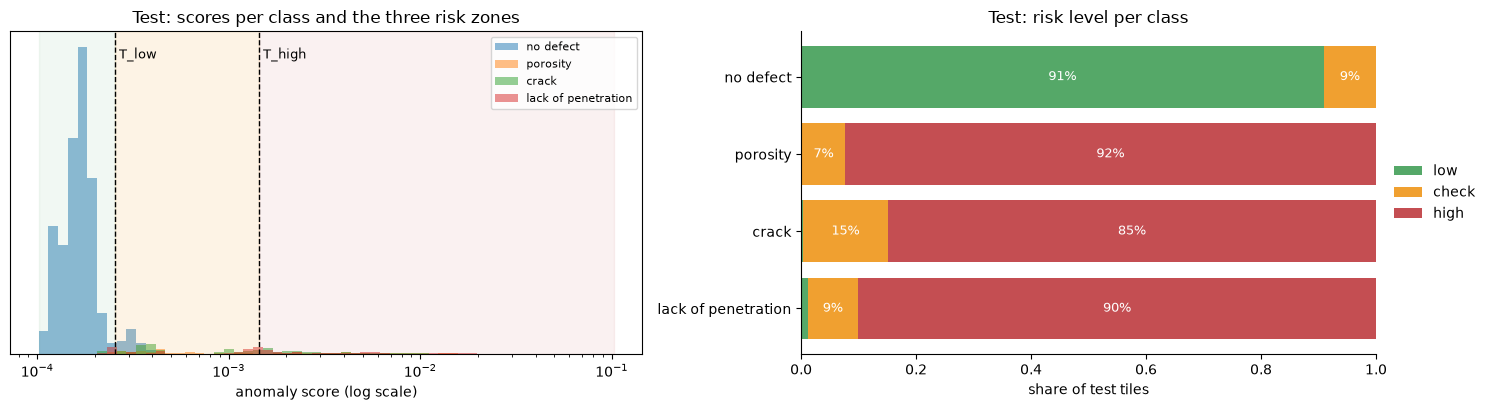

In [27]:
colours = {"low": "#55A868", "check": "#F0A030", "high": "#C44E52"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

# left: test scores per class with both thresholds
ax = axes[0]
bins = np.logspace(np.log10(et.min()), np.log10(et.max()), 60)
for label in order:
    ax.hist(et[labels_test == label], bins=bins, alpha=0.5, density=True, label=label.replace("_", " "))
ax.axvspan(et.min(), T_LOW, color=colours["low"], alpha=0.08)
ax.axvspan(T_LOW, T_HIGH, color=colours["check"], alpha=0.12)
ax.axvspan(T_HIGH, et.max(), color=colours["high"], alpha=0.08)
for t, name in [(T_LOW, "T_low"), (T_HIGH, "T_high")]:
    ax.axvline(t, color="black", ls="--", lw=1)
    ax.text(t, ax.get_ylim()[1] * 0.95, f" {name}", fontsize=9, va="top")
ax.set_xscale("log"); ax.set_yticks([])
ax.set(xlabel="anomaly score (log scale)", title="Test: scores per class and the three risk zones")
ax.legend(fontsize=8, loc="upper right")

# right: share of each class in each level (test)
ax = axes[1]
left = np.zeros(len(order))
for lvl in RISK_LEVELS:
    vals = test_levels[lvl].to_numpy()
    ax.barh([l.replace("_", " ") for l in order], vals, left=left, color=colours[lvl], label=lvl)
    for y, (v, l0) in enumerate(zip(vals, left)):
        if v > 0.04:
            ax.text(l0 + v / 2, y, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += vals
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set(xlabel="share of test tiles", title="Test: risk level per class")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "risk_levels_test.png", dpi=120, bbox_inches="tight")
plt.show()

In [28]:
# Add the risk levels to the server config (Step 9 file)
config_path = MODEL_APP_DIR / "anomaly_ae_config.json"
config = json.loads(config_path.read_text())
config["risk_levels"] = {
    "low": f"score <= {T_LOW:.6f}: looks like a sound weld",
    "check": f"{T_LOW:.6f} < score <= {T_HIGH:.6f}: unusual, an inspector should look",
    "high": f"score > {T_HIGH:.6f}: strongly abnormal, inspect first",
}
config["t_low"] = T_LOW
config["t_high"] = T_HIGH
config["t_low_rule"] = f"{TARGET_RECALL:.0%} of defect validation tiles score above it"
config["t_high_rule"] = f"only {SOUND_HIGH_RATE:.1%} of sound validation tiles score above it"
config_path.write_text(json.dumps(config, indent=2))

for label in order:
    s = score_png(MODEL_APP_DIR / "examples" / f"{label}.png")
    print(f"{label:20s} score {s:.5f}  ->  risk level: {risk_level(np.array([s]))[0].upper()}")

no_defect            score 0.00017  ->  risk level: LOW
porosity             score 0.01113  ->  risk level: HIGH
crack                score 0.00477  ->  risk level: HIGH
lack_of_penetration  score 0.01036  ->  risk level: HIGH


### Step 10 – what the risk levels give us

![Risk levels on the test set](../figures/risk_levels_test.png)

**Thresholds (chosen on validation):** T_low = **0.000255**, T_high = **0.001442**. T_low is lower than the single 95% threshold of Step 7 (0.000345): we deliberately accept more false alarms to miss fewer defects.

**On the 4 unseen test welds:**

| Class | 🟢 low | 🟠 check | 🔴 high |
|---|---|---|---|
| no defect | **90.9%** | 9.1% | 0.0% |
| porosity | 0.2% | 7.4% | **92.4%** |
| crack | 0.3% | 14.7% | **84.9%** |
| lack of penetration | 1.1% | 8.8% | **90.1%** |

- **Safety:** only **11 of 2,153 defect tiles (0.5%)** end up in "low", i.e. would be skipped. On validation, where the threshold was set to 98%, the miss rate was 2%; the test welds are easier.
- **Workload:** **91% of sound tiles** can be skipped. The inspector looks at the "check" pile (9% of sound tiles plus the borderline defects) and starts with "high".
- **"High" is reliable:** no sound test tile reached "high" (0.5% on validation, by design), so a red tile is almost certainly a real defect.
- **Cracks land in "check" most often (15%)**: they are faint, as seen before. That is exactly where a human eye is needed.

**The trade-off table** shows the choice is adjustable. Asking for 99% of defects on validation sends 19% of sound tiles to "check"; 95% sends only 5% but misses more. **98% is our compromise**, and the two numbers (`TARGET_RECALL`, `SOUND_HIGH_RATE`) are one line to change. In a real project the inspection team, not the data scientist, should make this call.

## 13. Conclusions

**1. The data needed real cleaning before any model.** RIAWELC as published leaks: every test image was also in training, and tiles of the same weld were spread over all splits. We removed 2,514 duplicates and rebuilt the split **by weld** (29 welds). Without this, the scores would have been inflated and meaningless.

**2. An autoencoder trained only on sound welds finds all three defect types.** It never saw a defect, yet on unseen welds it separates defects from sound tiles with **ROC AUC ≈ 0.99** (0.990 validation, 0.999 test). This is the key advantage over a classifier: no defect labels are needed to train it, so it can also flag defect types nobody labelled.

**3. It learns more than "defects are high contrast".** The contrast-only baseline reaches 0.946. The autoencoder beats it everywhere, most on **cracks** (0.985 vs 0.926), the most dangerous defect.

**4. Smaller was better.** The winner is the smallest model: **convolutional, 64 px, code of 32 numbers, 0.7 M parameters**.
- 64 px beat 128 px: the lower resolution averages away the X-ray grain, which an autoencoder cannot copy anyway, while the defects survive the resize.
- A bigger code (128) did not help: it lets the model copy defects too.
- The dense model was worst with 17× more parameters: it ignores which pixels are neighbours.

**5. The output is usable by an inspector.** With the risk levels, 91% of sound tiles can be skipped, 99.5% of defect tiles are sent to a human, and the error map shows where to look. The model runs from a 2.8 MB ONNX file, ready for the server.

**6. Limitations to state honestly.**
- **Small number of welds:** 29 in total, 4 in test. The test result (0.999) is partly luck of which welds landed there; "about 0.99 on unseen welds" is the fair claim, and the difference between setups A and D (0.987 vs 0.990) is within that uncertainty.
- **One lab, one X-ray setup:** results may not transfer to other equipment.
- **Tile-level labels:** we can check whether a tile is flagged, not whether the error map points at the right spot.
- **The model rebuilds every tile as a smooth gradient.** On grainy radiographs part of the score comes from texture rather than the defect.
- **Training was noisy:** setups B and C stopped early (epoch 5–6), so they may be slightly under-rated.
- **Screening aid, not a verdict:** acceptance under welding standards depends on defect size and plate thickness, which the dataset does not contain.